## Initial Data Inspection

This section examines the structure and quality of the student dataset, including its dimensions, data types, missing values, descriptive statistics, and target class distribution.

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv("data.csv", sep=";")

# Display the first five rows
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [2]:
# Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Number of features:", df.shape[1] - 1)

Number of rows: 4424
Number of columns: 37
Number of features: 36


**Dataset Overview**

The dataset contains 4,424 student records and 37 columns, including 36 input features and one target variable. The target variable represents three academic outcomes: Dropout, Enrolled, and Graduate.

In [3]:
# Inspect column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

**Data Types Analysis**

The dataset contains 29 integer columns, 7 floating-point columns, and 1 object column (Target). Most features are stored numerically, although some represent categorical variables encoded as integers.

In [4]:
# Check missing values
missing_values = df.isnull().sum()

print(missing_values)
print("\nTotal missing values:", missing_values.sum())

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

### Missing Values Analysis

The dataset contains no missing values across all 37 columns. This indicates that all 4,424 student records are complete, and no missing-value imputation is required during preprocessing.

In [5]:
# Display descriptive statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance\t,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


**Statistical Summary Analysis**

The dataset contains 4,424 student records. The average age at enrollment is 23.27 years, and the average admission grade is 126.98. The average first-semester grade (10.64) is slightly higher than the second-semester grade (10.23). Some numerical variables represent categorical codes and should not be interpreted as continuous measurements.

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


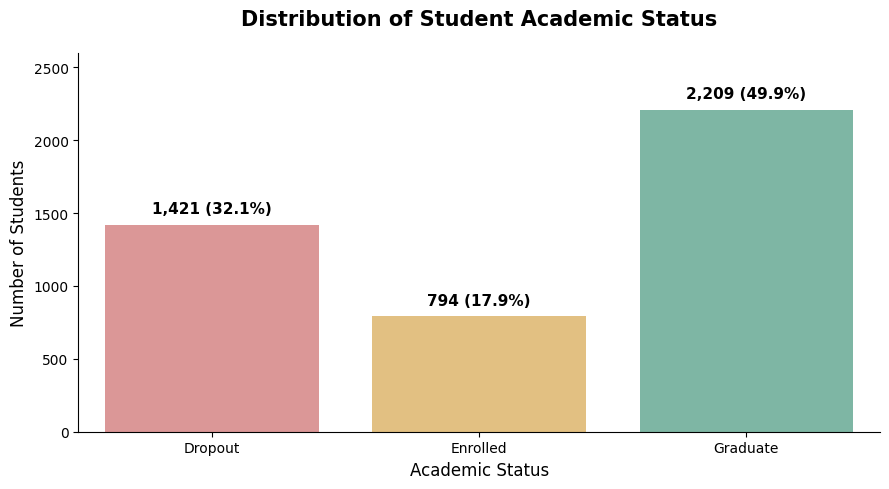

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count students in each academic status
order = ["Dropout", "Enrolled", "Graduate"]
class_counts = df["Target"].value_counts()
print(class_counts)

# Create a professional bar chart
plt.figure(figsize=(9, 5))
colors = ["#E78B8B", "#F2C572", "#75BFA8"]

ax = sns.barplot(
    x=order,
    y=[class_counts[status] for status in order],
    hue=order,
    palette=colors,
    legend=False
)

# Add counts and percentages above bars
total = len(df)

for bar in ax.patches:
    count = int(bar.get_height())
    percentage = count / total * 100
    ax.annotate(
        f"{count:,} ({percentage:.1f}%)",
        (bar.get_x() + bar.get_width()/2, count),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        xytext=(0, 6),
        textcoords="offset points"
    )

plt.title("Distribution of Student Academic Status",
          fontsize=15, fontweight="bold", pad=20)
plt.xlabel("Academic Status", fontsize=12)
plt.ylabel("Number of Students", fontsize=12)
plt.ylim(0, 2600)
sns.despine()
plt.tight_layout()
plt.show()


**Class Distribution Analysis**

The dataset contains 2,209 graduates, 1,421 dropouts, and 794 enrolled students. Graduates represent the largest class, while enrolled students represent the smallest. This indicates a class imbalance that should be considered during preprocessing and model evaluation.